<a href="https://www.kaggle.com/code/lalit7881/indian-smart-phone-purchase-eda?scriptVersionId=366787638" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")
# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/aryansingh2000/indian-smart-phone-purchase/indian_smartphone_purchases_1m.xlsx


In [2]:
file_path = "/kaggle/input/datasets/aryansingh2000/indian-smart-phone-purchase/indian_smartphone_purchases_1m.xlsx"

df = pd.read_excel(file_path)

# Display dataset
display(df.head())

# Dataset information
print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

,customer_id,first_name,last_name,age,gender,city,state,pincode,brand,model,...,storage_gb,price_inr,discount_applied_percent,purchase_platform,payment_method,is_exchange_offer,delivery_type,customer_rating,feedback_sentiment,purchase_date
0,CUST_0987232,Vishiya_987232,Iyer,19,Male,Hubballi,Karnataka,680821,Vivo,Vivo V30,...,256,25016.60,25,Amazon,Cash on Delivery,True,Standard,2,Positive,2025-12-07
1,CUST_0079955,Araan_79955,Patel,57,Female,Ahmedabad,Gujarat,273306,OPPO,OPPO A79,...,128,12111.57,15,Brand Official Website,Net Banking,False,Standard,4,Neutral,2026-04-14
2,CUST_0567131,Ishaan_567131,Sharma,27,Female,Udaipur,Rajasthan,543226,Samsung,Galaxy S24,...,128,49072.37,0,Amazon,UPI,True,Standard,4,Positive,2026-09-06
3,CUST_0500892,Tanitya,Gupta,19,Male,Jabalpur,Madhya Pradesh,432742,iQOO,iQOO Neo 9 Pro,...,256,14496.07,10,Flipkart,UPI,False,Standard,4,Positive,2026-01-18
4,CUST_0055400,Kavvi_55400,Desai,49,Male,Rajkot,Gujarat,418008,Samsung,Galaxy F14,...,256,69362.50,0,Amazon,UPI,False,Standard,5,Positive,2025-12-15


Dataset Shape: (1000000, 21)

Column Names:
['customer_id', 'first_name', 'last_name', 'age', 'gender', 'city', 'state', 'pincode', 'brand', 'model', 'ram_gb', 'storage_gb', 'price_inr', 'discount_applied_percent', 'purchase_platform', 'payment_method', 'is_exchange_offer', 'delivery_type', 'customer_rating', 'feedback_sentiment', 'purchase_date']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 21 columns):
 #   Column                    Non-Null Count    Dtype         
---  ------                    --------------    -----         
 0   customer_id               1000000 non-null  object        
 1   first_name                1000000 non-null  object        
 2   last_name                 1000000 non-null  object        
 3   age                       1000000 non-null  int64         
 4   gender                    1000000 non-null  object        
 5   city                      1000000 non-null  object        
 6  

In [3]:
df.tail()

,customer_id,first_name,last_name,age,gender,city,state,pincode,brand,model,...,storage_gb,price_inr,discount_applied_percent,purchase_platform,payment_method,is_exchange_offer,delivery_type,customer_rating,feedback_sentiment,purchase_date
999995,CUST_0259179,Aadi_259179,Patel,58,Female,Rajkot,Gujarat,610691,Samsung,Galaxy S23 FE,...,256,73769.99,10,Amazon,UPI,False,Standard,4,Positive,2026-03-26
999996,CUST_0365839,Karanan_365839,Gupta,48,Male,Kanpur,Uttar Pradesh,249091,Xiaomi,POCO X6,...,128,24040.09,15,Flipkart,UPI,False,Express,1,Negative,2026-02-05
999997,CUST_0131933,Kiransh_131933,Naidu,46,Female,Nizamabad,Telangana,679588,Xiaomi,POCO X6,...,256,20341.07,20,Amazon,Net Banking,False,Standard,4,Positive,2026-09-01
999998,CUST_0671156,Yashhna_671156,Pandey,40,Male,Agra,Uttar Pradesh,590510,Samsung,Galaxy A55,...,256,72529.60,5,Brand Official Website,UPI,False,Standard,5,Positive,2026-06-07
999999,CUST_0121959,Saaan_121959,Patel,62,Female,Surat,Gujarat,184178,Xiaomi,Redmi 13C,...,128,9896.79,0,Amazon,UPI,False,Express,5,Positive,2026-09-24


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 21 columns):
 #   Column                    Non-Null Count    Dtype         
---  ------                    --------------    -----         
 0   customer_id               1000000 non-null  object        
 1   first_name                1000000 non-null  object        
 2   last_name                 1000000 non-null  object        
 3   age                       1000000 non-null  int64         
 4   gender                    1000000 non-null  object        
 5   city                      1000000 non-null  object        
 6   state                     1000000 non-null  object        
 7   pincode                   1000000 non-null  int64         
 8   brand                     1000000 non-null  object        
 9   model                     1000000 non-null  object        
 10  ram_gb                    1000000 non-null  int64         
 11  storage_gb                1000000 non-null  int64  

In [5]:
df.describe()

,age,pincode,ram_gb,storage_gb,price_inr,discount_applied_percent,customer_rating,purchase_date
count,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.00000,1000000
mean,41.000062,482750.208291,7.198148,166.240896,34160.204559,8.606950,4.01086,2026-05-01 21:43:24.528000
min,18.000000,110005.000000,4.000000,64.000000,8000.010000,0.000000,1.00000,2025-11-01 00:00:00
25%,29.000000,296381.500000,4.000000,128.000000,16895.565000,5.000000,4.00000,2026-01-31 00:00:00
50%,41.000000,483026.500000,6.000000,128.000000,24365.465000,10.000000,4.00000,2026-05-02 00:00:00
75%,53.000000,669122.000000,8.000000,256.000000,47305.695000,10.000000,5.00000,2026-08-01 00:00:00
max,64.000000,855114.000000,16.000000,512.000000,144999.890000,30.000000,5.00000,2026-10-31 00:00:00
std,13.564537,215172.628685,3.115645,105.448730,25526.436421,7.003864,0.98424,NaN


In [6]:
df.isnull().sum()

customer_id                 0
first_name                  0
last_name                   0
age                         0
gender                      0
city                        0
state                       0
pincode                     0
brand                       0
model                       0
ram_gb                      0
storage_gb                  0
price_inr                   0
discount_applied_percent    0
purchase_platform           0
payment_method              0
is_exchange_offer           0
delivery_type               0
customer_rating             0
feedback_sentiment          0
purchase_date               0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.dtypes

customer_id                         object
first_name                          object
last_name                           object
age                                  int64
gender                              object
city                                object
state                               object
pincode                              int64
brand                               object
model                               object
ram_gb                               int64
storage_gb                           int64
price_inr                          float64
discount_applied_percent             int64
purchase_platform                   object
payment_method                      object
is_exchange_offer                     bool
delivery_type                       object
customer_rating                      int64
feedback_sentiment                  object
purchase_date               datetime64[ns]
dtype: object

In [9]:
df.shape

(1000000, 21)

In [10]:
df.columns

Index(['customer_id', 'first_name', 'last_name', 'age', 'gender', 'city',
       'state', 'pincode', 'brand', 'model', 'ram_gb', 'storage_gb',
       'price_inr', 'discount_applied_percent', 'purchase_platform',
       'payment_method', 'is_exchange_offer', 'delivery_type',
       'customer_rating', 'feedback_sentiment', 'purchase_date'],
      dtype='object')

In [11]:
df.nunique()

customer_id                 1000000
first_name                   857916
last_name                        67
age                              47
gender                            3
city                             55
state                            11
pincode                      550286
brand                             9
model                            45
ram_gb                            5
storage_gb                        4
price_inr                    900844
discount_applied_percent          7
purchase_platform                 6
payment_method                    5
is_exchange_offer                 2
delivery_type                     3
customer_rating                   5
feedback_sentiment                3
purchase_date                   365
dtype: int64

## EDA

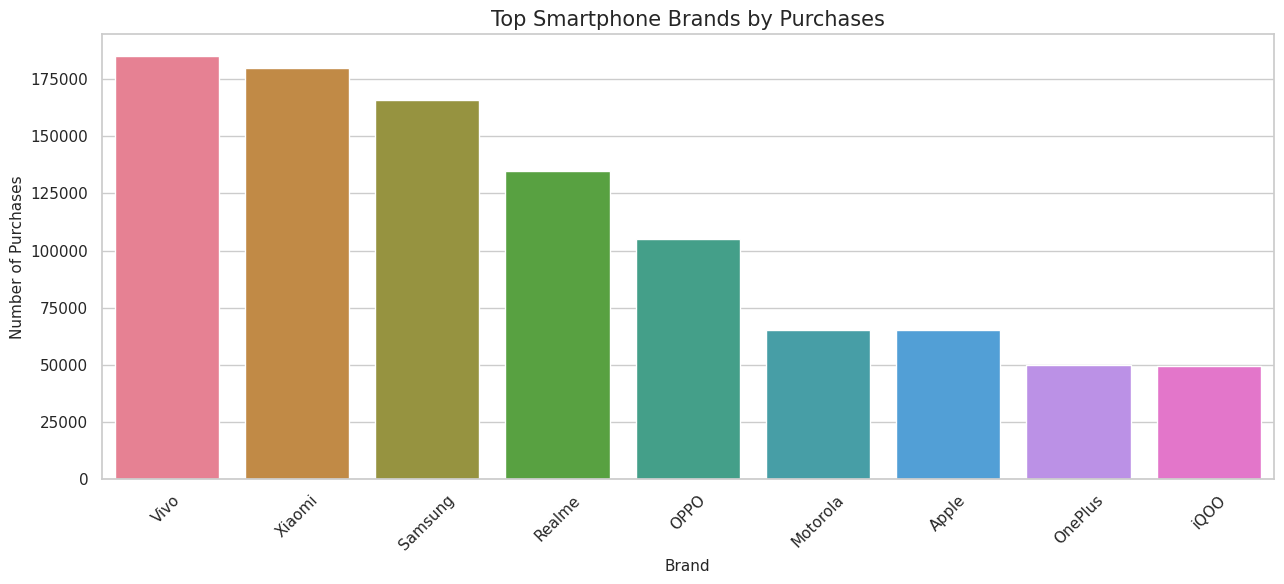

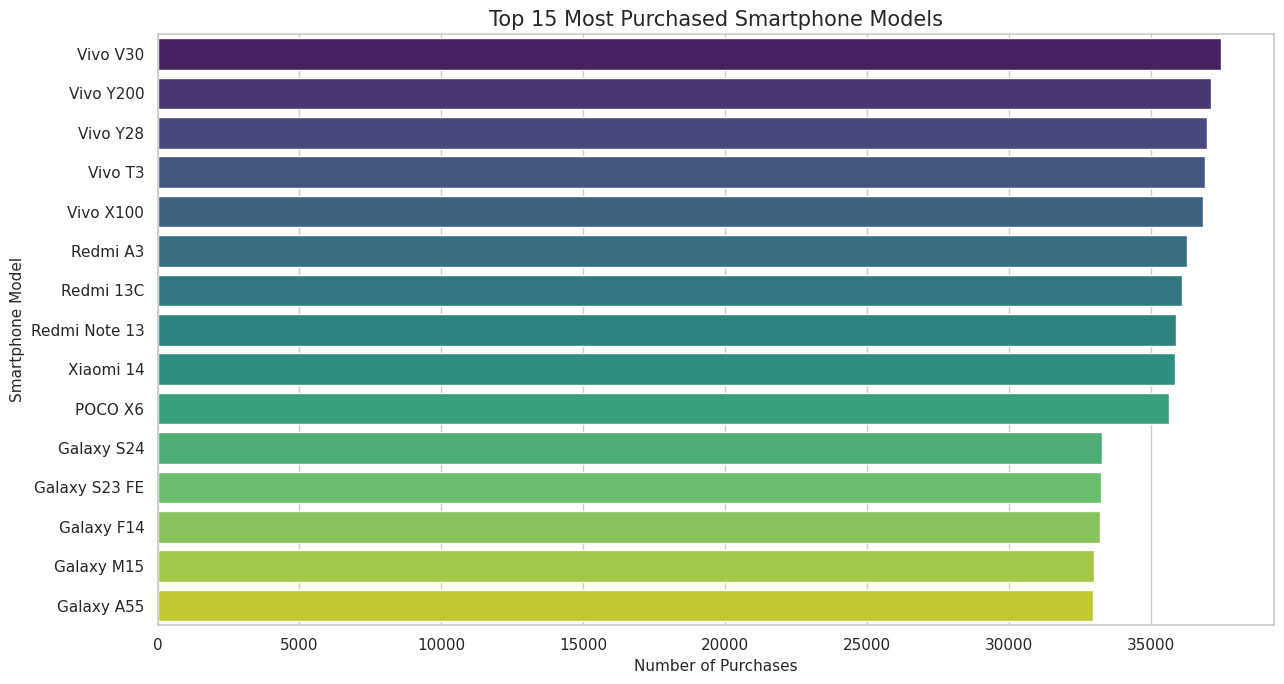

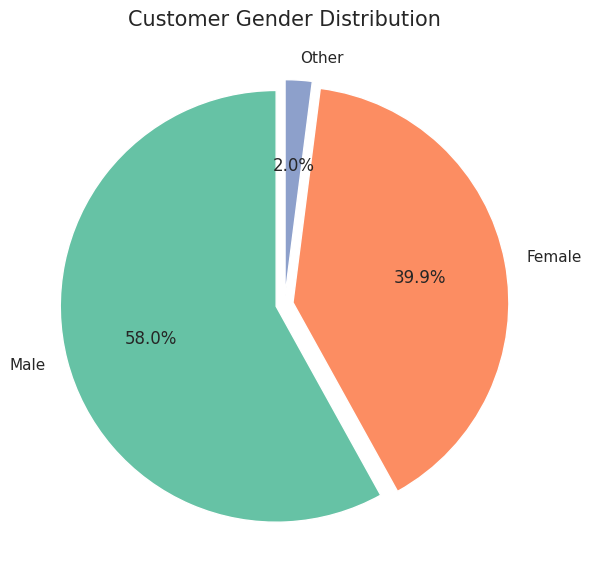

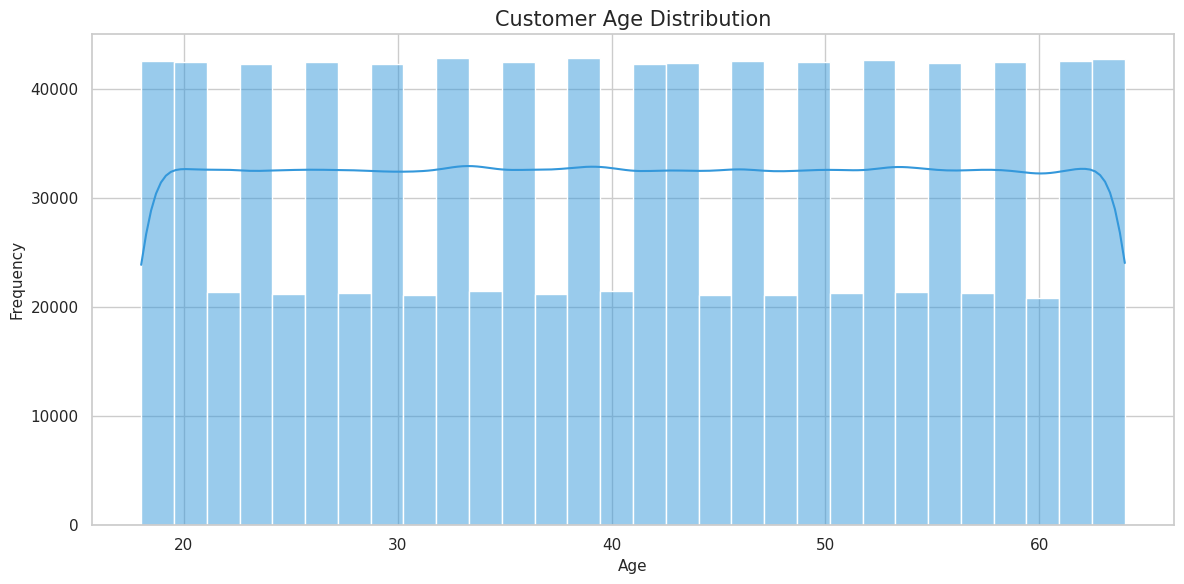

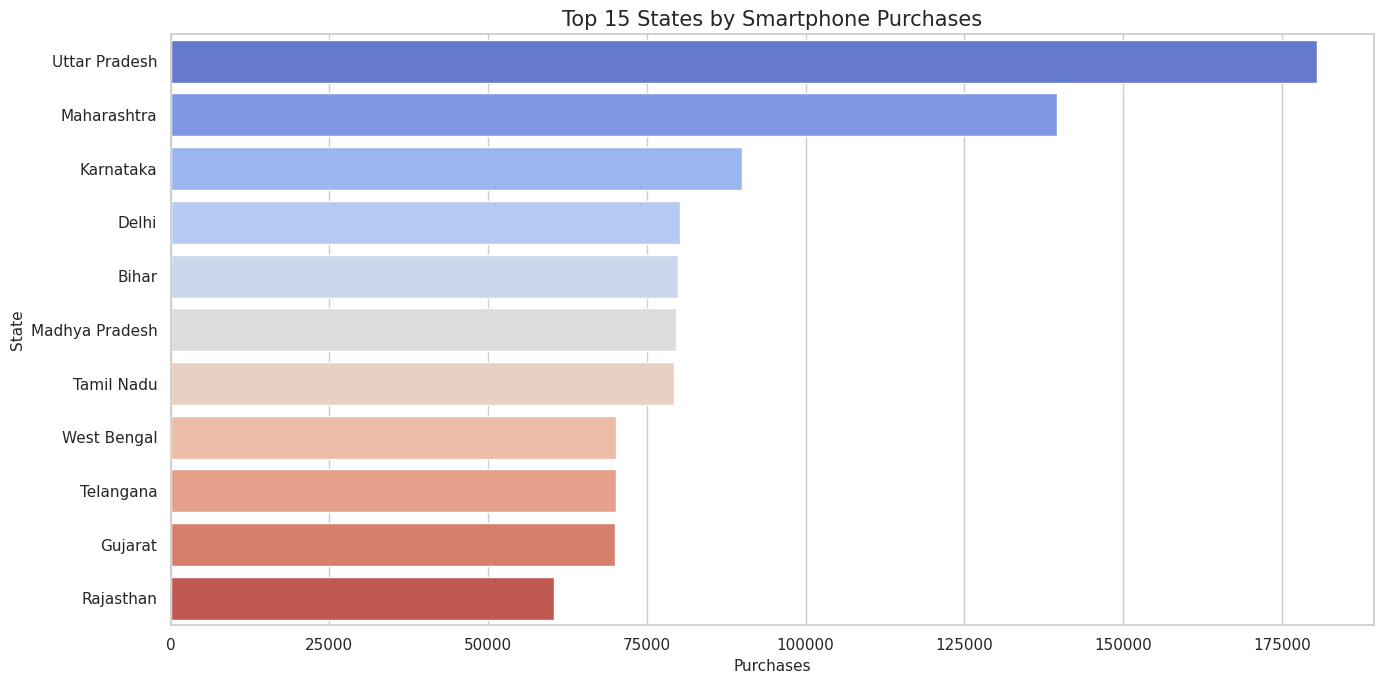

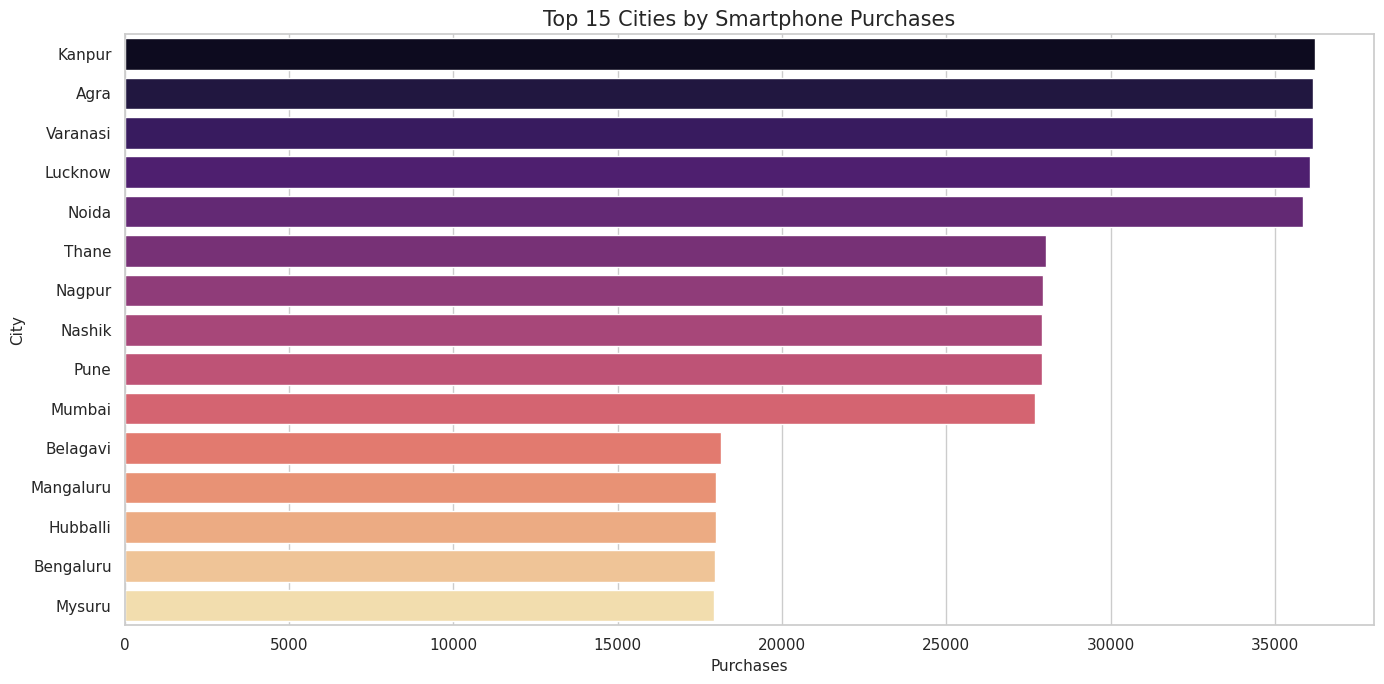

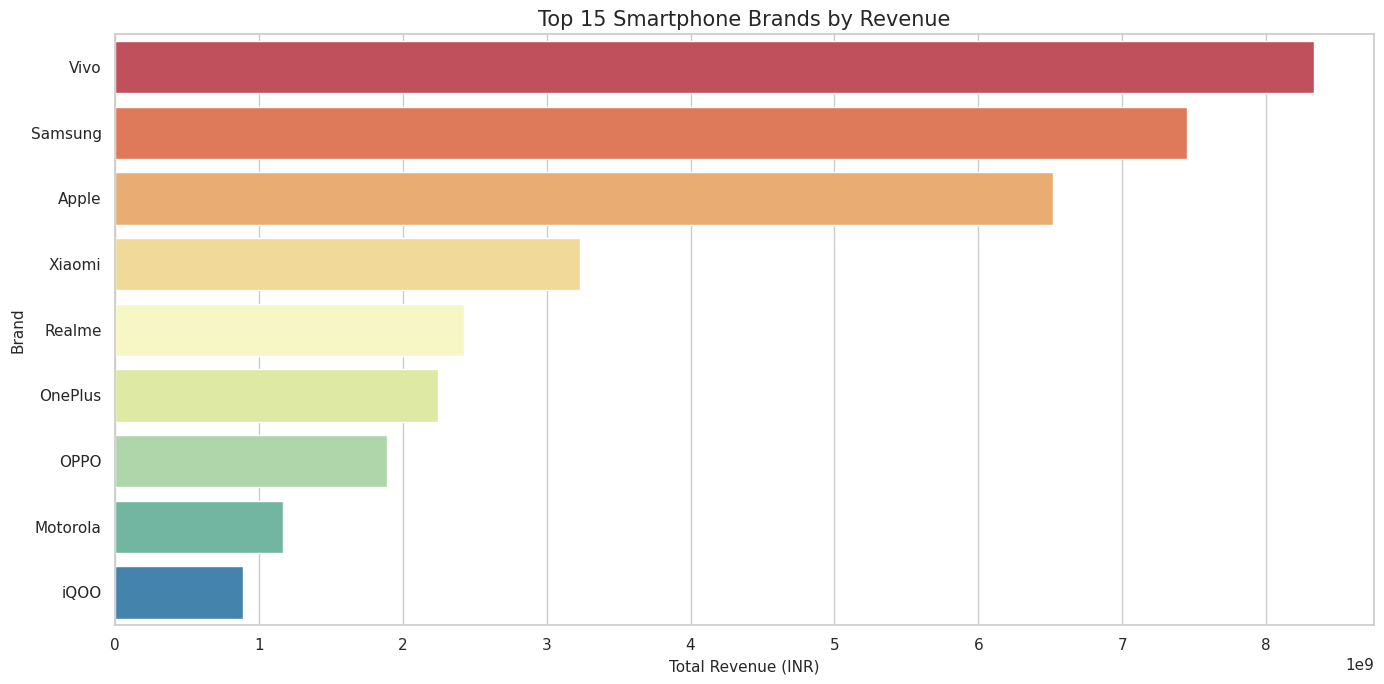

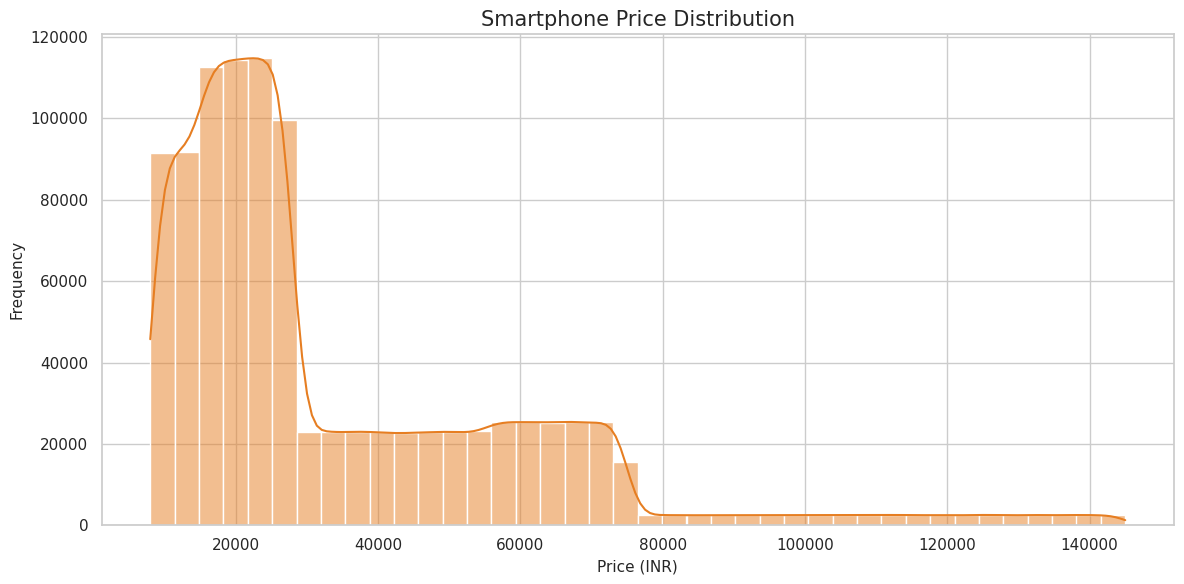

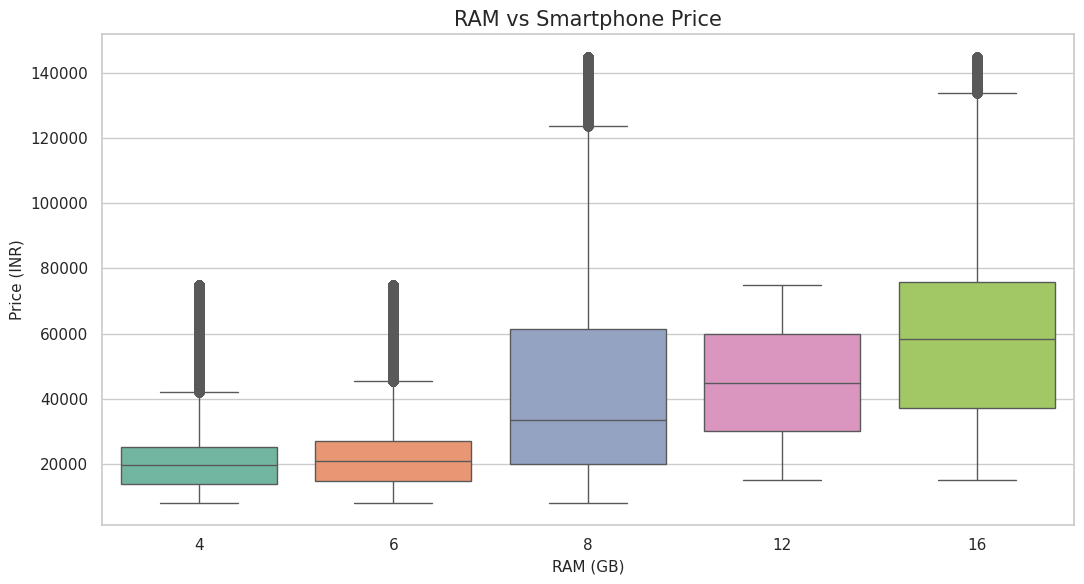

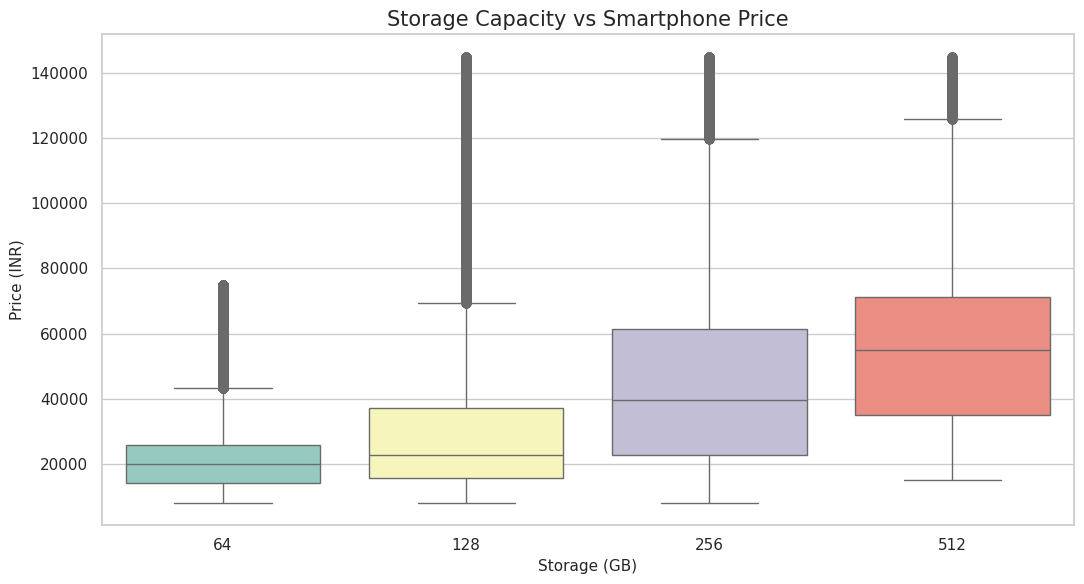

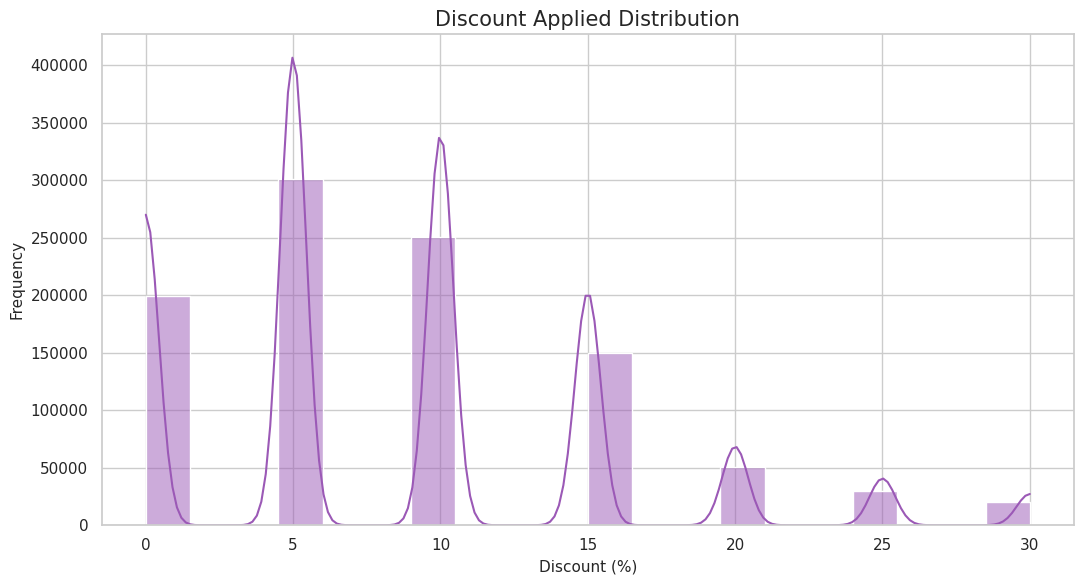

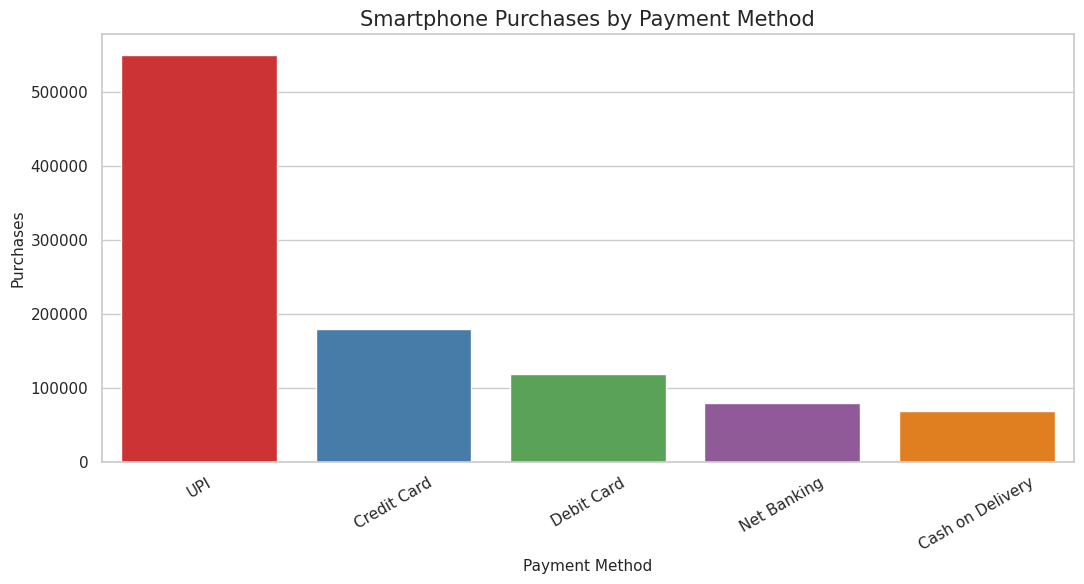

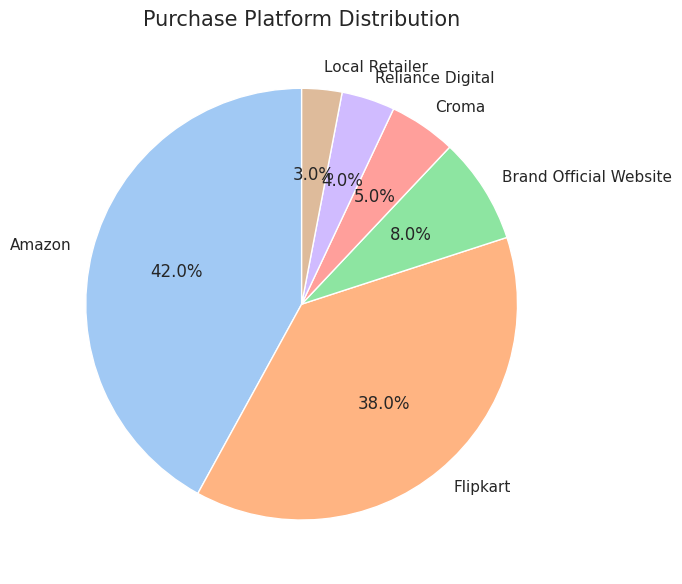

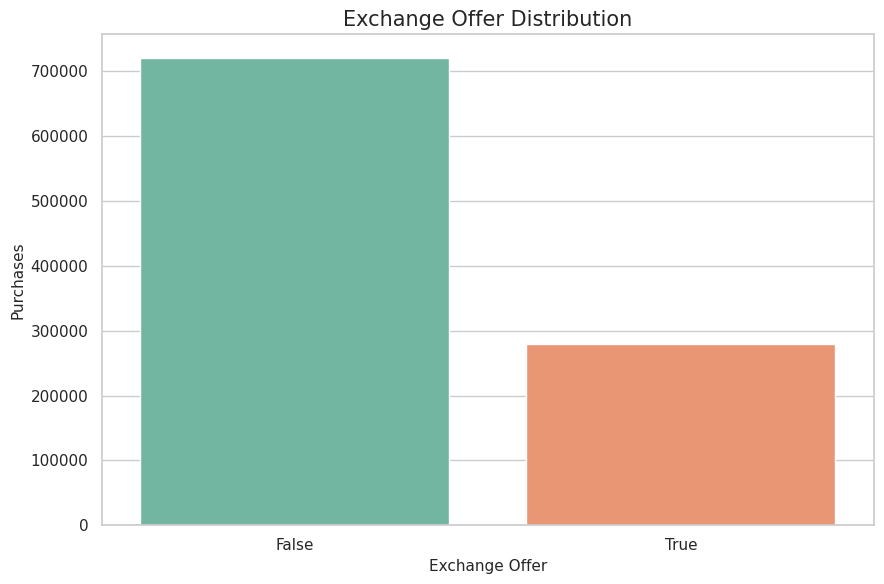

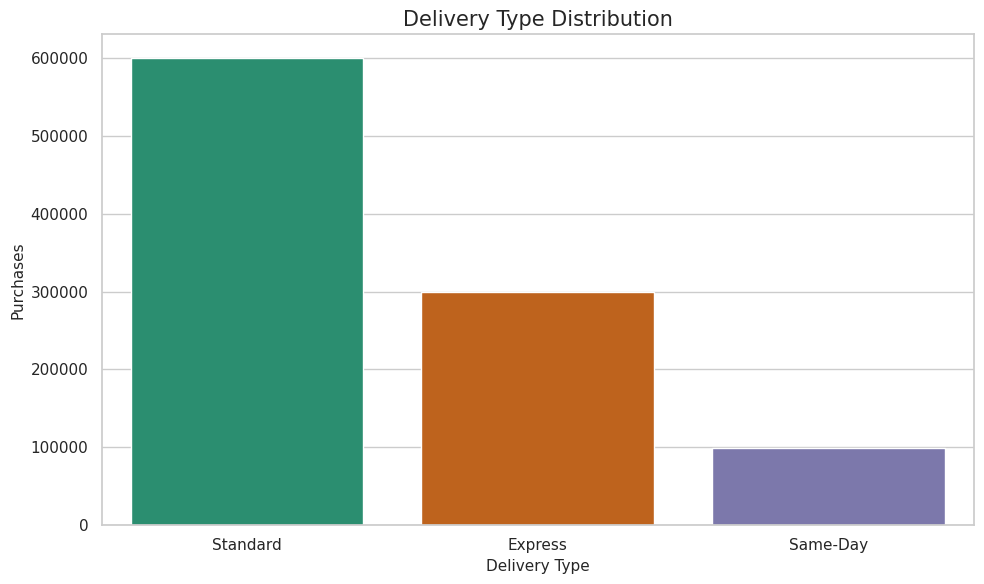

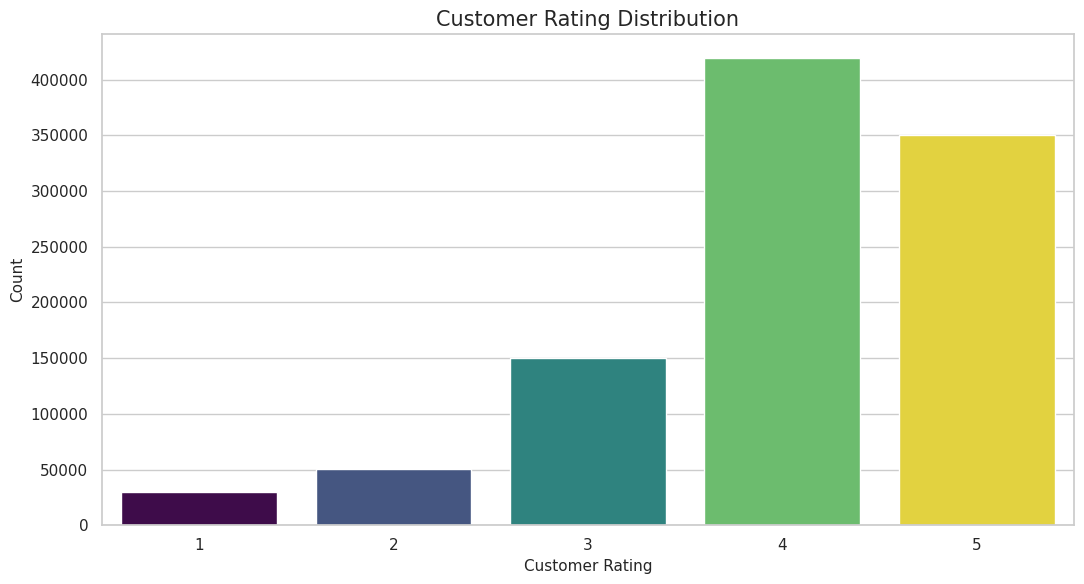

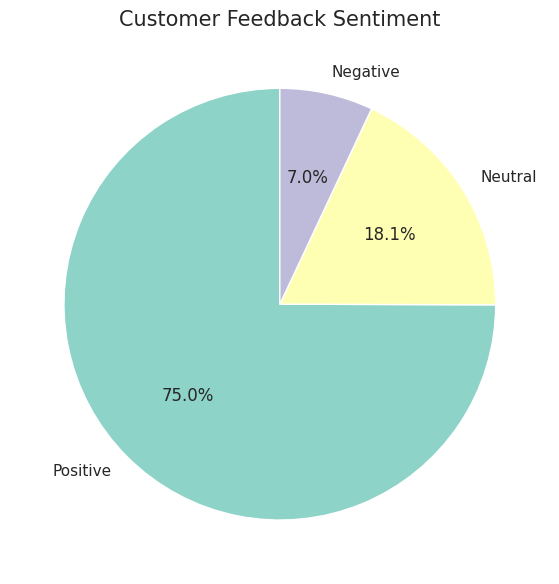

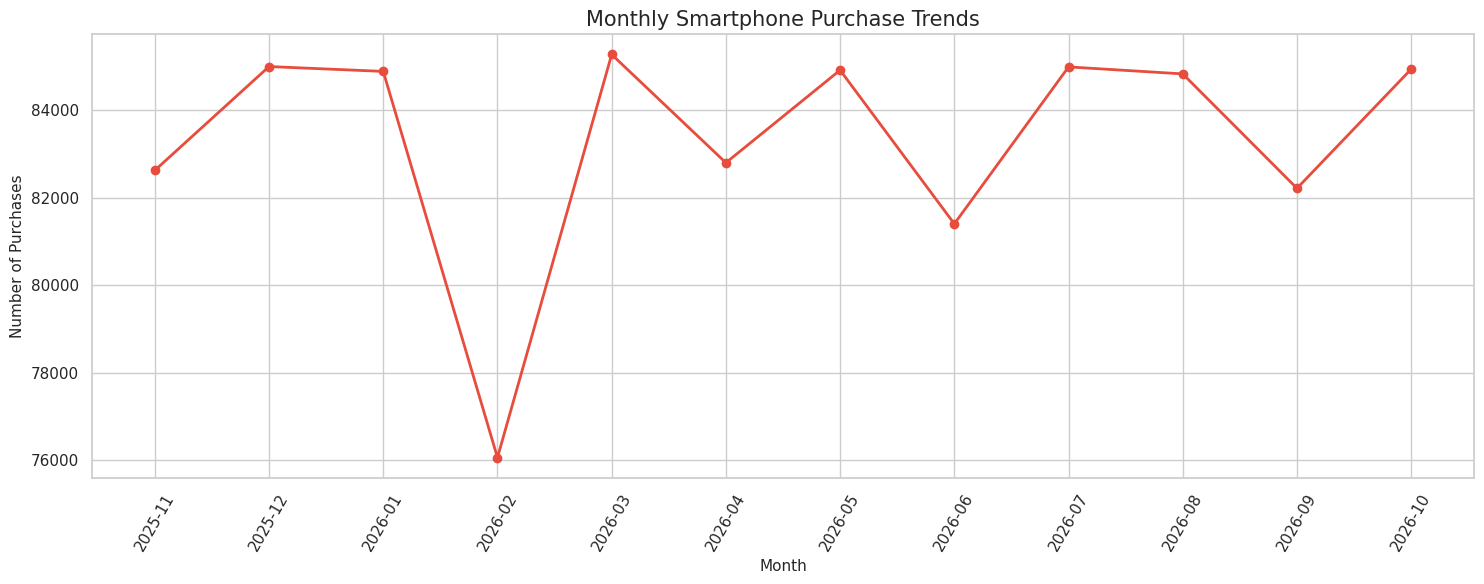

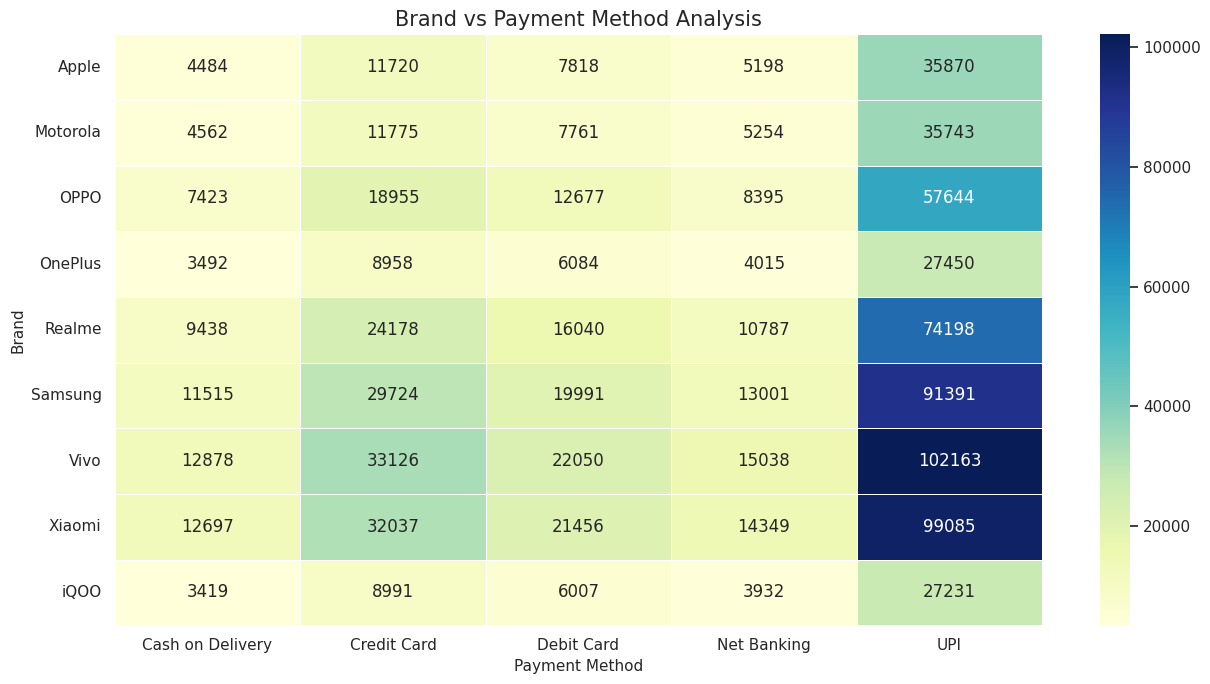

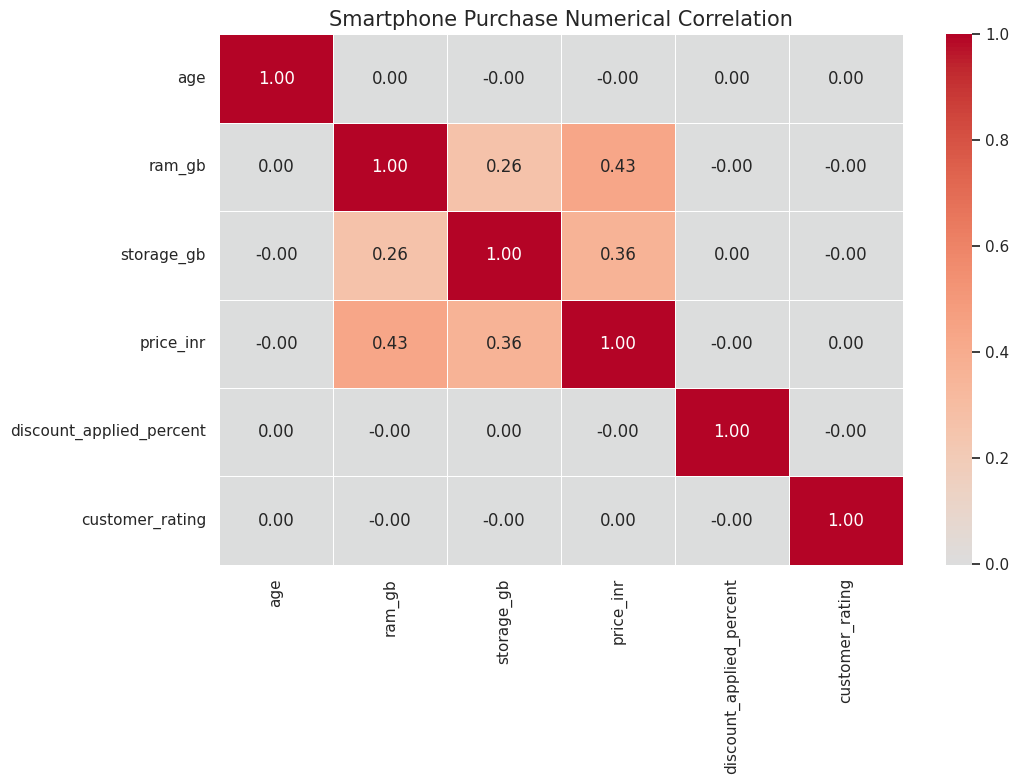

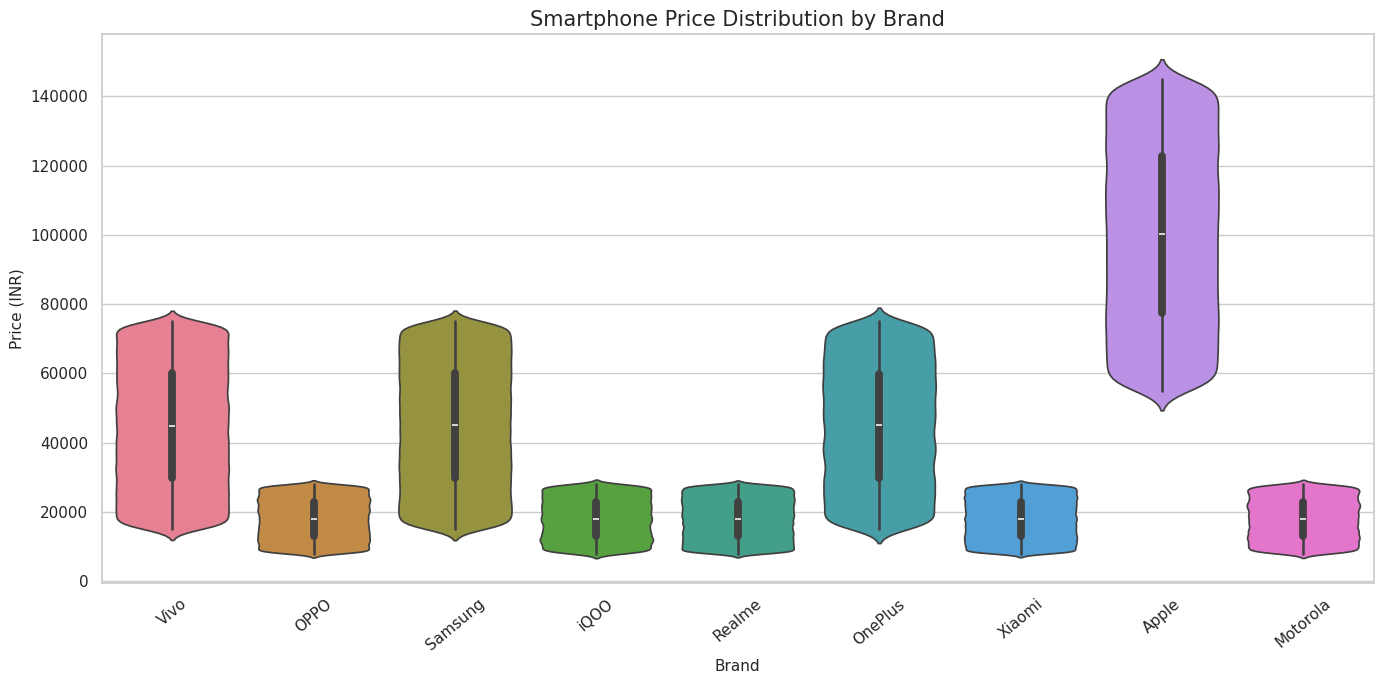

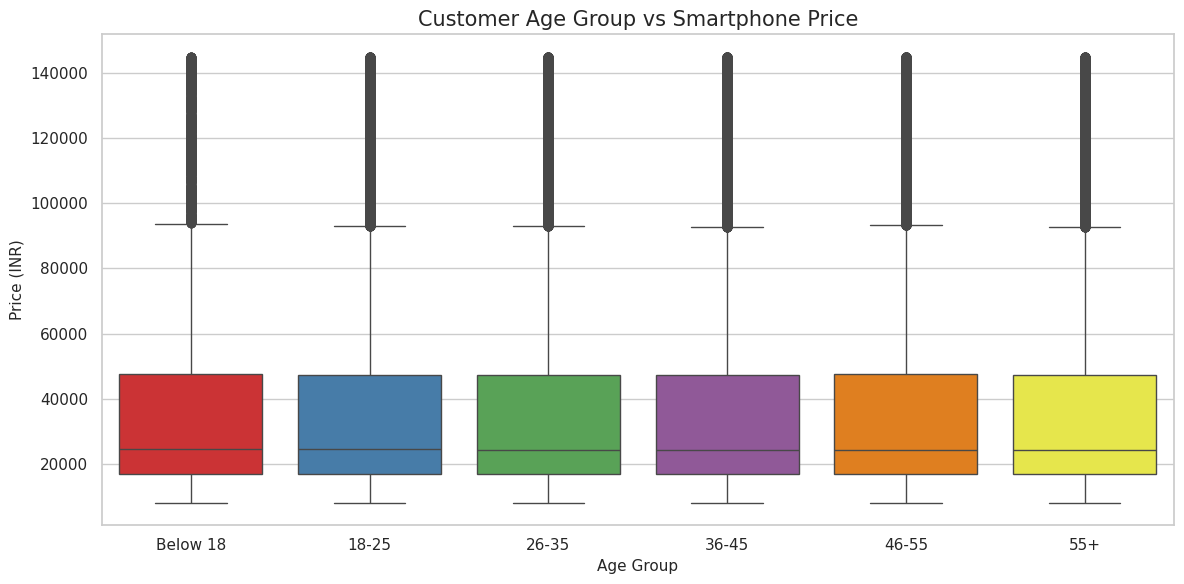

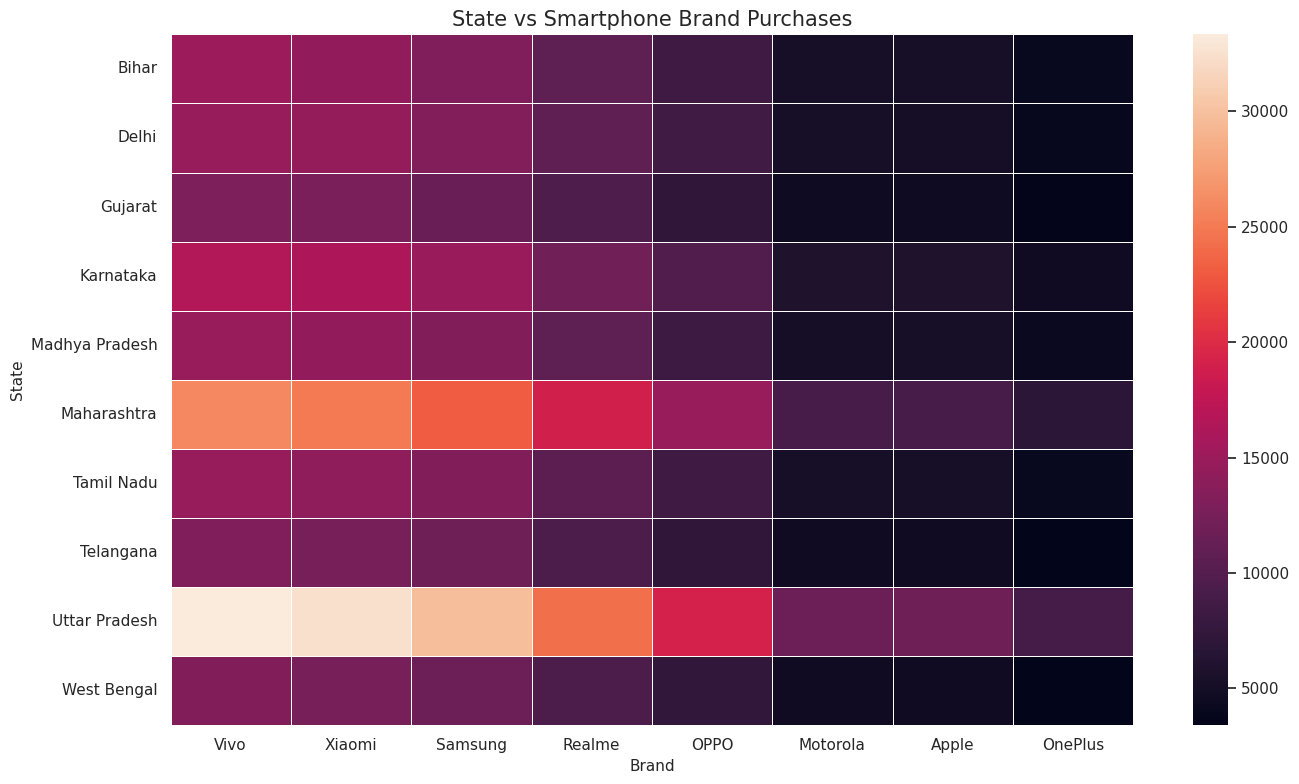

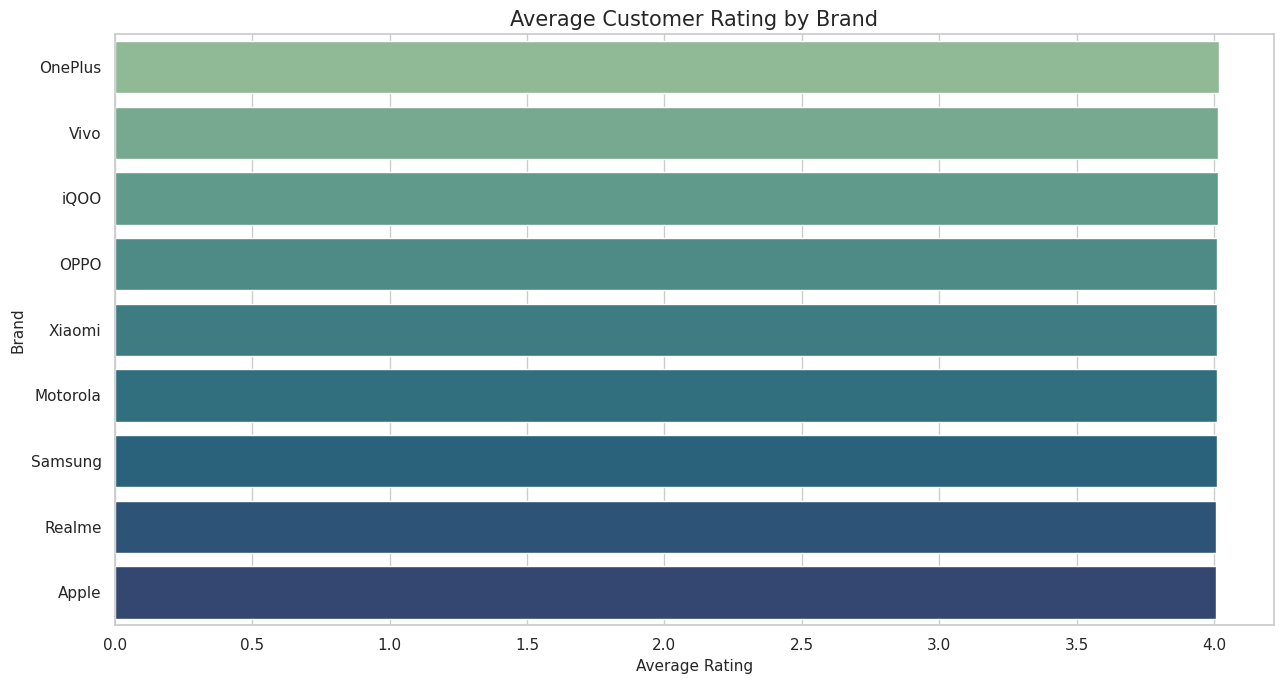


========== SMARTPHONE PURCHASE SUMMARY ==========
Total Purchases: 1000000
Unique Customers: 1000000
Total Brands: 9
Average Smartphone Price: 34160.2
Maximum Smartphone Price: 144999.89
Minimum Smartphone Price: 8000.01
Average Customer Age: 41.0
Average Customer Rating: 4.01
Total Purchase Value (INR): 34160204558.6

Top Selling Brand:
brand
Vivo    185255
Name: count, dtype: int64

Most Popular Payment Method:
payment_method
UPI    550775
Name: count, dtype: int64

Most Popular Purchase Platform:
purchase_platform
Amazon    420156
Name: count, dtype: int64

========== VISUALIZATION COMPLETED ==========


In [12]:
# -------------------- DATA CLEANING --------------------

df = df.drop_duplicates().copy()

numeric_cols = [
    'age', 'ram_gb', 'storage_gb', 'price_inr',
    'discount_applied_percent', 'customer_rating'
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

df['purchase_date'] = pd.to_datetime(
    df['purchase_date'], errors='coerce'
)

# Remove rows with invalid essential values
df = df.dropna(subset=['brand', 'price_inr'])

# Feature engineering
df['purchase_month'] = df['purchase_date'].dt.month_name()
df['purchase_year'] = df['purchase_date'].dt.year
df['purchase_month_year'] = (
    df['purchase_date'].dt.to_period('M').astype(str)
)

df['age_group'] = pd.cut(
    df['age'],
    bins=[0, 18, 25, 35, 45, 55, 100],
    labels=['Below 18', '18-25', '26-35',
            '36-45', '46-55', '55+']
)

# -------------------- VISUAL SETTINGS --------------------

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['axes.titlesize'] = 15
plt.rcParams['axes.labelsize'] = 11

colors = sns.color_palette("husl", 15)

def show_plot():
    plt.tight_layout()
    plt.show()
    plt.close()

# ============================================================
# 1. BRAND-WISE PURCHASE DISTRIBUTION
# ============================================================

plt.figure(figsize=(13, 6))

brand_counts = df['brand'].value_counts().head(15)

sns.barplot(
    x=brand_counts.index,
    y=brand_counts.values,
    hue=brand_counts.index,
    palette="husl",
    legend=False
)

plt.title("Top Smartphone Brands by Purchases")
plt.xlabel("Brand")
plt.ylabel("Number of Purchases")
plt.xticks(rotation=45)
show_plot()

# ============================================================
# 2. TOP 15 SMARTPHONE MODELS
# ============================================================

plt.figure(figsize=(13, 7))

model_counts = df['model'].value_counts().head(15)

sns.barplot(
    x=model_counts.values,
    y=model_counts.index,
    hue=model_counts.index,
    palette="viridis",
    legend=False
)

plt.title("Top 15 Most Purchased Smartphone Models")
plt.xlabel("Number of Purchases")
plt.ylabel("Smartphone Model")
show_plot()

# ============================================================
# 3. GENDER DISTRIBUTION
# ============================================================

plt.figure(figsize=(8, 6))

gender_counts = df['gender'].value_counts()

plt.pie(
    gender_counts.values,
    labels=gender_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=sns.color_palette("Set2", len(gender_counts)),
    explode=[0.04] * len(gender_counts)
)

plt.title("Customer Gender Distribution")
plt.ylabel("")
show_plot()

# ============================================================
# 4. AGE DISTRIBUTION
# ============================================================

plt.figure(figsize=(12, 6))

sns.histplot(
    df['age'].dropna(),
    bins=30,
    kde=True,
    color="#3498DB"
)

plt.title("Customer Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")
show_plot()

# ============================================================
# 5. STATE-WISE PURCHASES
# ============================================================

plt.figure(figsize=(14, 7))

state_counts = df['state'].value_counts().head(15)

sns.barplot(
    x=state_counts.values,
    y=state_counts.index,
    hue=state_counts.index,
    palette="coolwarm",
    legend=False
)

plt.title("Top 15 States by Smartphone Purchases")
plt.xlabel("Purchases")
plt.ylabel("State")
show_plot()

# ============================================================
# 6. TOP 15 CITIES
# ============================================================

plt.figure(figsize=(14, 7))

city_counts = df['city'].value_counts().head(15)

sns.barplot(
    x=city_counts.values,
    y=city_counts.index,
    hue=city_counts.index,
    palette="magma",
    legend=False
)

plt.title("Top 15 Cities by Smartphone Purchases")
plt.xlabel("Purchases")
plt.ylabel("City")
show_plot()

# ============================================================
# 7. BRAND-WISE REVENUE
# ============================================================

plt.figure(figsize=(14, 7))

brand_revenue = (
    df.groupby('brand')['price_inr']
    .sum()
    .sort_values(ascending=False)
    .head(15)
)

sns.barplot(
    x=brand_revenue.values,
    y=brand_revenue.index,
    hue=brand_revenue.index,
    palette="Spectral",
    legend=False
)

plt.title("Top 15 Smartphone Brands by Revenue")
plt.xlabel("Total Revenue (INR)")
plt.ylabel("Brand")
show_plot()

# ============================================================
# 8. SMARTPHONE PRICE DISTRIBUTION
# ============================================================

plt.figure(figsize=(12, 6))

sns.histplot(
    df['price_inr'],
    bins=40,
    kde=True,
    color="#E67E22"
)

plt.title("Smartphone Price Distribution")
plt.xlabel("Price (INR)")
plt.ylabel("Frequency")
show_plot()

# ============================================================
# 9. RAM VS SMARTPHONE PRICE
# ============================================================

plt.figure(figsize=(11, 6))

sns.boxplot(
    data=df,
    x='ram_gb',
    y='price_inr',
    hue='ram_gb',
    palette="Set2",
    legend=False
)

plt.title("RAM vs Smartphone Price")
plt.xlabel("RAM (GB)")
plt.ylabel("Price (INR)")
show_plot()

# ============================================================
# 10. STORAGE VS SMARTPHONE PRICE
# ============================================================

plt.figure(figsize=(11, 6))

sns.boxplot(
    data=df,
    x='storage_gb',
    y='price_inr',
    hue='storage_gb',
    palette="Set3",
    legend=False
)

plt.title("Storage Capacity vs Smartphone Price")
plt.xlabel("Storage (GB)")
plt.ylabel("Price (INR)")
show_plot()

# ============================================================
# 11. DISCOUNT DISTRIBUTION
# ============================================================

plt.figure(figsize=(11, 6))

sns.histplot(
    df['discount_applied_percent'].dropna(),
    bins=20,
    kde=True,
    color="#9B59B6"
)

plt.title("Discount Applied Distribution")
plt.xlabel("Discount (%)")
plt.ylabel("Frequency")
show_plot()

# ============================================================
# 12. PAYMENT METHOD ANALYSIS
# ============================================================

plt.figure(figsize=(11, 6))

payment_counts = df['payment_method'].value_counts()

sns.barplot(
    x=payment_counts.index,
    y=payment_counts.values,
    hue=payment_counts.index,
    palette="Set1",
    legend=False
)

plt.title("Smartphone Purchases by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Purchases")
plt.xticks(rotation=30)
show_plot()

# ============================================================
# 13. PURCHASE PLATFORM ANALYSIS
# ============================================================

plt.figure(figsize=(10, 6))

platform_counts = df['purchase_platform'].value_counts()

plt.pie(
    platform_counts.values,
    labels=platform_counts.index,
    autopct='%1.1f%%',
    colors=sns.color_palette("pastel", len(platform_counts)),
    startangle=90
)

plt.title("Purchase Platform Distribution")
plt.ylabel("")
show_plot()

# ============================================================
# 14. EXCHANGE OFFER ANALYSIS
# ============================================================

plt.figure(figsize=(9, 6))

exchange_counts = df['is_exchange_offer'].astype(str).value_counts()

sns.barplot(
    x=exchange_counts.index,
    y=exchange_counts.values,
    hue=exchange_counts.index,
    palette="Set2",
    legend=False
)

plt.title("Exchange Offer Distribution")
plt.xlabel("Exchange Offer")
plt.ylabel("Purchases")
show_plot()

# ============================================================
# 15. DELIVERY TYPE ANALYSIS
# ============================================================

plt.figure(figsize=(10, 6))

delivery_counts = df['delivery_type'].value_counts()

sns.barplot(
    x=delivery_counts.index,
    y=delivery_counts.values,
    hue=delivery_counts.index,
    palette="Dark2",
    legend=False
)

plt.title("Delivery Type Distribution")
plt.xlabel("Delivery Type")
plt.ylabel("Purchases")
show_plot()

# ============================================================
# 16. CUSTOMER RATING DISTRIBUTION
# ============================================================

plt.figure(figsize=(11, 6))

sns.countplot(
    data=df,
    x='customer_rating',
    hue='customer_rating',
    palette="viridis",
    legend=False
)

plt.title("Customer Rating Distribution")
plt.xlabel("Customer Rating")
plt.ylabel("Count")
show_plot()

# ============================================================
# 17. FEEDBACK SENTIMENT ANALYSIS
# ============================================================

plt.figure(figsize=(10, 6))

sentiment_counts = df['feedback_sentiment'].value_counts()

plt.pie(
    sentiment_counts.values,
    labels=sentiment_counts.index,
    autopct='%1.1f%%',
    colors=sns.color_palette("Set3", len(sentiment_counts)),
    startangle=90
)

plt.title("Customer Feedback Sentiment")
plt.ylabel("")
show_plot()

# ============================================================
# 18. MONTHLY PURCHASE TREND
# ============================================================

monthly_sales = (
    df.dropna(subset=['purchase_date'])
    .groupby('purchase_month_year')
    .size()
)

plt.figure(figsize=(15, 6))

plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker='o',
    linewidth=2,
    color="#E74C3C"
)

plt.title("Monthly Smartphone Purchase Trends")
plt.xlabel("Month")
plt.ylabel("Number of Purchases")
plt.xticks(rotation=60)
show_plot()

# ============================================================
# 19. BRAND VS PAYMENT METHOD
# ============================================================

top_brands = df['brand'].value_counts().head(10).index

cross_data = pd.crosstab(
    df[df['brand'].isin(top_brands)]['brand'],
    df['payment_method']
)

plt.figure(figsize=(13, 7))

sns.heatmap(
    cross_data,
    annot=True,
    fmt='g',
    cmap="YlGnBu",
    linewidths=0.5
)

plt.title("Brand vs Payment Method Analysis")
plt.xlabel("Payment Method")
plt.ylabel("Brand")
show_plot()

# ============================================================
# 20. NUMERICAL CORRELATION HEATMAP
# ============================================================

plt.figure(figsize=(11, 8))

correlation = df[
    ['age', 'ram_gb', 'storage_gb', 'price_inr',
     'discount_applied_percent', 'customer_rating']
].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    center=0
)

plt.title("Smartphone Purchase Numerical Correlation")
show_plot()

# ============================================================
# 21. PRICE BY BRAND
# ============================================================

plt.figure(figsize=(14, 7))

top_brands = df['brand'].value_counts().head(10).index

sns.violinplot(
    data=df[df['brand'].isin(top_brands)],
    x='brand',
    y='price_inr',
    hue='brand',
    palette="husl",
    legend=False
)

plt.title("Smartphone Price Distribution by Brand")
plt.xlabel("Brand")
plt.ylabel("Price (INR)")
plt.xticks(rotation=40)
show_plot()

# ============================================================
# 22. AGE GROUP VS SMARTPHONE PRICE
# ============================================================

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x='age_group',
    y='price_inr',
    hue='age_group',
    palette="Set1",
    legend=False
)

plt.title("Customer Age Group vs Smartphone Price")
plt.xlabel("Age Group")
plt.ylabel("Price (INR)")
show_plot()

# ============================================================
# 23. STATE VS BRAND PURCHASES
# ============================================================

top_states = df['state'].value_counts().head(10).index
top_brands = df['brand'].value_counts().head(8).index

state_brand = pd.crosstab(
    df[df['state'].isin(top_states)]['state'],
    df[df['state'].isin(top_states)]['brand']
)

state_brand = state_brand[top_brands]

plt.figure(figsize=(14, 8))

sns.heatmap(
    state_brand,
    cmap="rocket",
    linewidths=0.4
)

plt.title("State vs Smartphone Brand Purchases")
plt.xlabel("Brand")
plt.ylabel("State")
show_plot()

# ============================================================
# 24. AVERAGE CUSTOMER RATING BY BRAND
# ============================================================

rating_brand = (
    df.groupby('brand')['customer_rating']
    .mean()
    .sort_values(ascending=False)
    .head(15)
)

plt.figure(figsize=(13, 7))

sns.barplot(
    x=rating_brand.values,
    y=rating_brand.index,
    hue=rating_brand.index,
    palette="crest",
    legend=False
)

plt.title("Average Customer Rating by Brand")
plt.xlabel("Average Rating")
plt.ylabel("Brand")
show_plot()

# ============================================================
# 25. FINAL DATA SUMMARY
# ============================================================

print("\n========== SMARTPHONE PURCHASE SUMMARY ==========")

print("Total Purchases:", len(df))
print("Unique Customers:", df['customer_id'].nunique())
print("Total Brands:", df['brand'].nunique())
print("Average Smartphone Price:", round(df['price_inr'].mean(), 2))
print("Maximum Smartphone Price:", df['price_inr'].max())
print("Minimum Smartphone Price:", df['price_inr'].min())
print("Average Customer Age:", round(df['age'].mean(), 2))
print("Average Customer Rating:", round(df['customer_rating'].mean(), 2))
print("Total Purchase Value (INR):", round(df['price_inr'].sum(), 2))

print("\nTop Selling Brand:")
print(df['brand'].value_counts().head(1))

print("\nMost Popular Payment Method:")
print(df['payment_method'].value_counts().head(1))

print("\nMost Popular Purchase Platform:")
print(df['purchase_platform'].value_counts().head(1))

print("\n========== VISUALIZATION COMPLETED ==========")


## Feature engineering


Target Distribution:
feedback_sentiment
Positive    749521
Neutral     180627
Negative     69852
Name: count, dtype: int64

Target Classes: ['Negative' 'Neutral' 'Positive']
Number of Classes: 3

Numeric Features: ['age', 'ram_gb', 'storage_gb', 'price_inr', 'discount_applied_percent', 'customer_rating', 'purchase_month', 'purchase_year', 'purchase_day', 'purchase_weekday']

Categorical Features: ['gender', 'city', 'state', 'brand', 'model', 'purchase_platform', 'payment_method', 'is_exchange_offer', 'delivery_type', 'purchase_month_year', 'age_group']

Training Shape: (800000, 21)
Testing Shape: (200000, 21)

Processed Training Shape: (800000, 167)
Processed Testing Shape: (200000, 167)

Training: Logistic Regression
Accuracy : 30.01 %
Precision: 60.01 %
Recall   : 30.01 %
F1 Score : 36.21 %
ROC AUC  : 0.5005


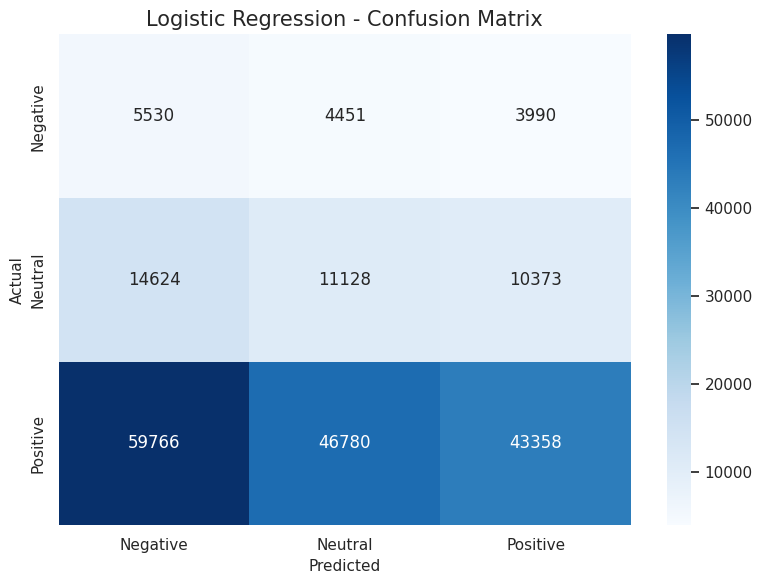


Training: Decision Tree
Accuracy : 25.56 %
Precision: 59.8 %
Recall   : 25.56 %
F1 Score : 26.97 %
ROC AUC  : 0.4988


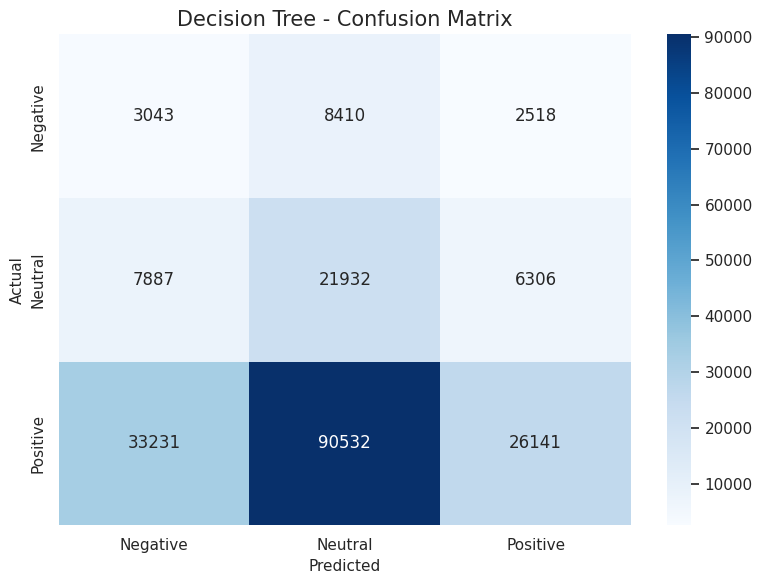


Training: Random Forest
Accuracy : 48.7 %
Precision: 60.02 %
Recall   : 48.7 %
F1 Score : 53.11 %
ROC AUC  : 0.5019


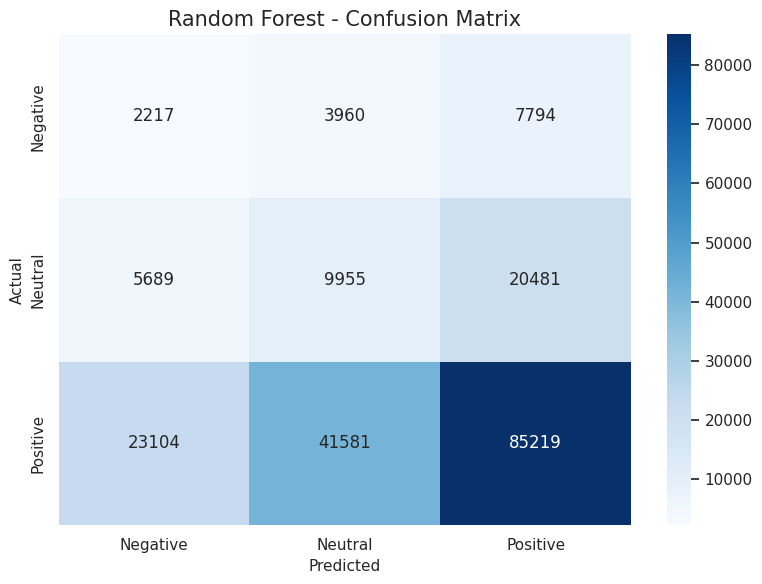


Training: Extra Trees
Accuracy : 41.08 %
Precision: 59.97 %
Recall   : 41.08 %
F1 Score : 47.24 %
ROC AUC  : 0.5008


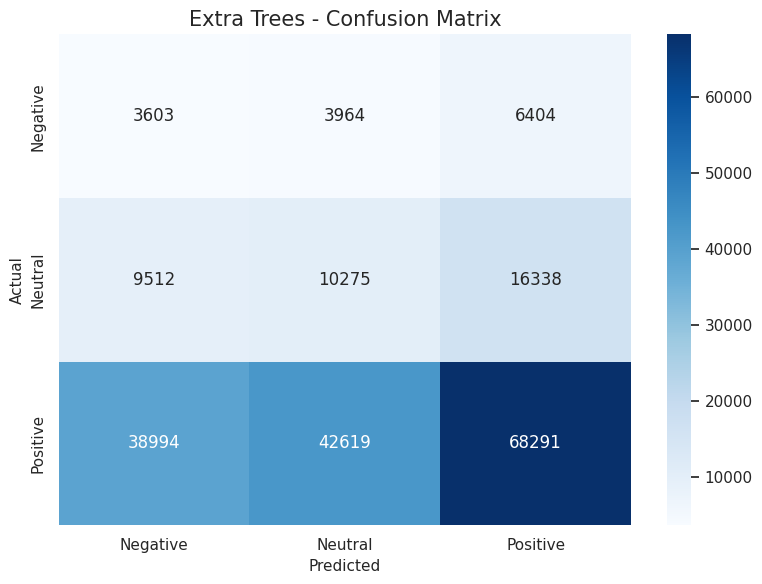


Training: Gradient Boosting
Accuracy : 74.95 %
Precision: 56.18 %
Recall   : 74.95 %
F1 Score : 64.22 %
ROC AUC  : 0.4988


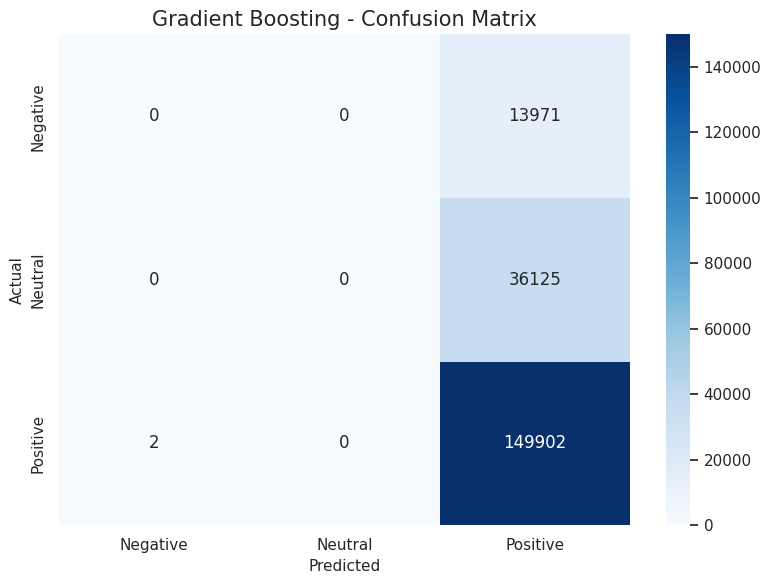


Training: KNN
Accuracy : 68.74 %
Precision: 59.87 %
Recall   : 68.74 %
F1 Score : 63.4 %
ROC AUC  : 0.5003


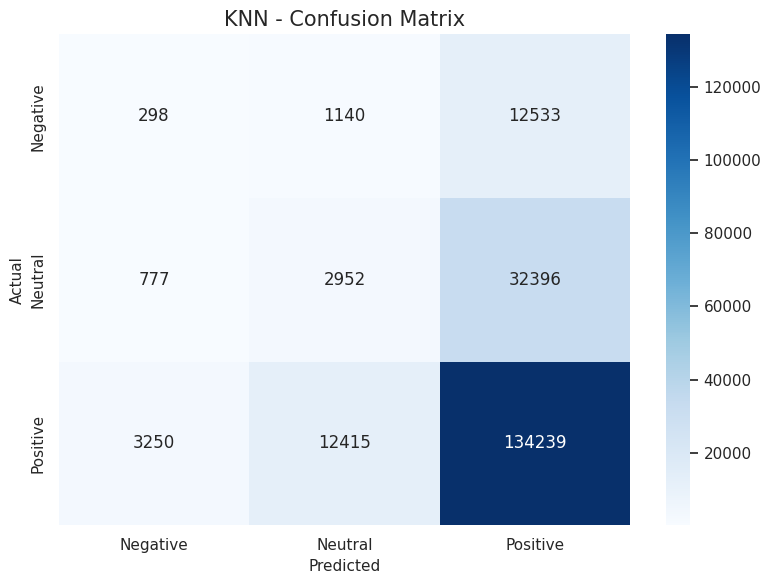


Training: Hist Gradient Boosting
Model Error: Sparse data was passed for X, but dense data is required. Use '.toarray()' to convert to a dense numpy array.

========== MODEL PERFORMANCE COMPARISON ==========


,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Random Forest,48.6955,60.0186,48.6955,53.1132,0.5019
1,Extra Trees,41.0845,59.9745,41.0845,47.2424,0.5008
2,Logistic Regression,30.0080,60.0079,30.0080,36.2090,0.5005
3,KNN,68.7445,59.8682,68.7445,63.4044,0.5003
4,Gradient Boosting,74.9510,56.1778,74.9510,64.2206,0.4988
5,Decision Tree,25.5580,59.7953,25.5580,26.9747,0.4988


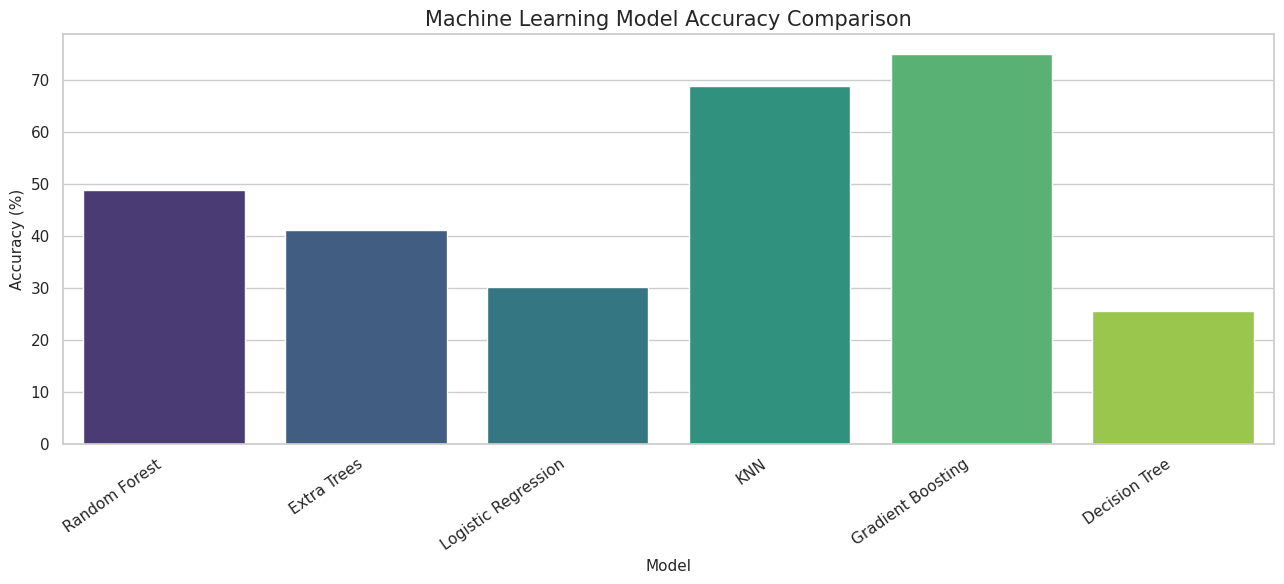

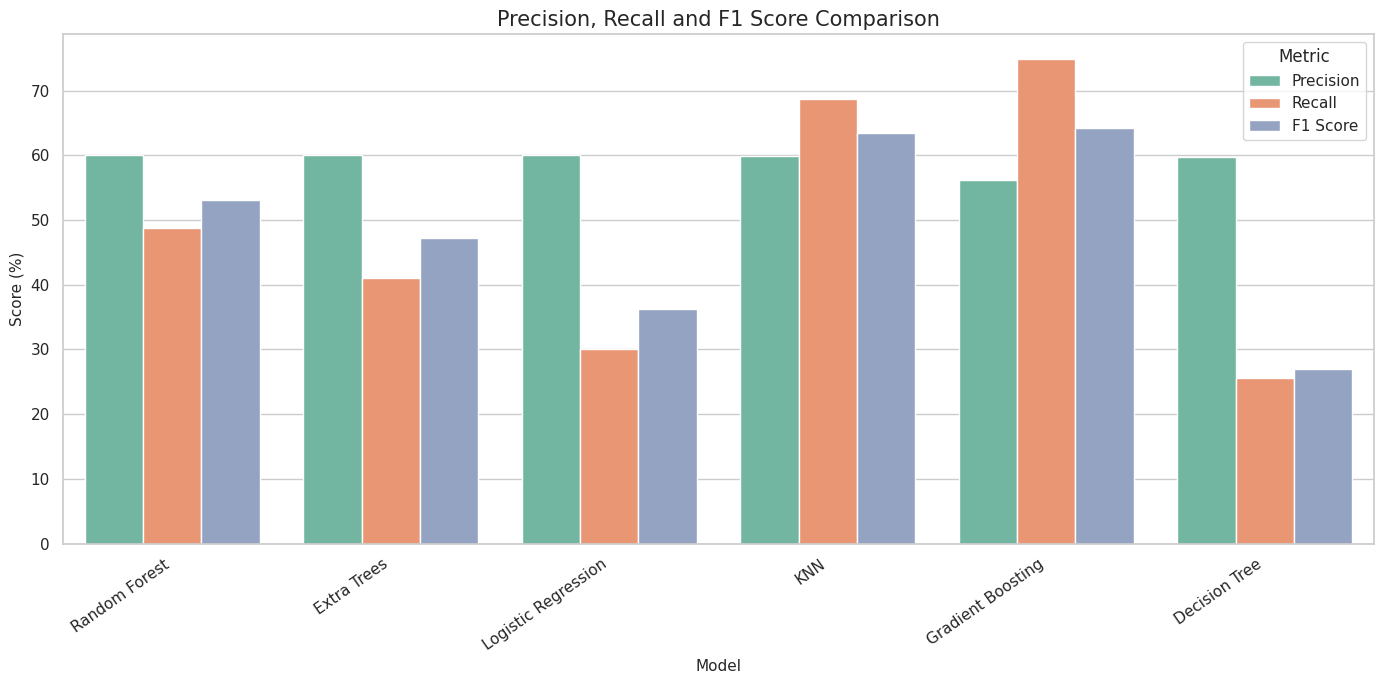

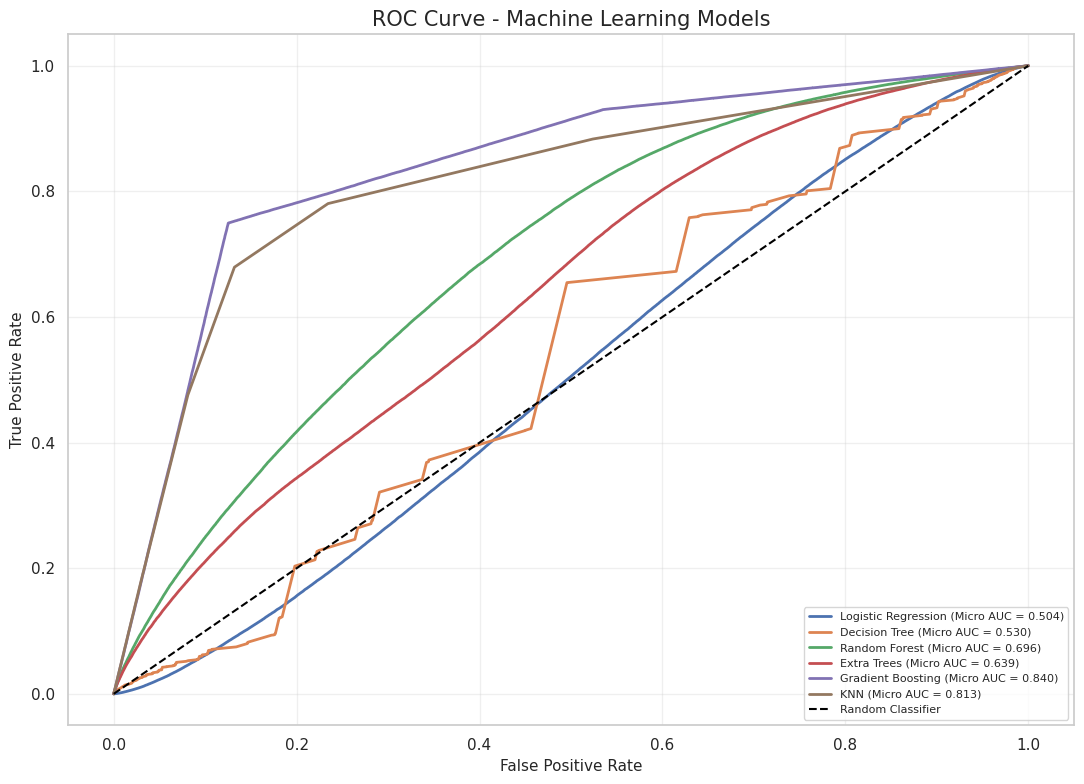


========== BEST MODEL ==========
Best Model: Random Forest

Classification Report:
              precision    recall  f1-score   support

    Negative       0.07      0.16      0.10     13971
     Neutral       0.18      0.28      0.22     36125
    Positive       0.75      0.57      0.65    149904

    accuracy                           0.49    200000
   macro avg       0.33      0.33      0.32    200000
weighted avg       0.60      0.49      0.53    200000



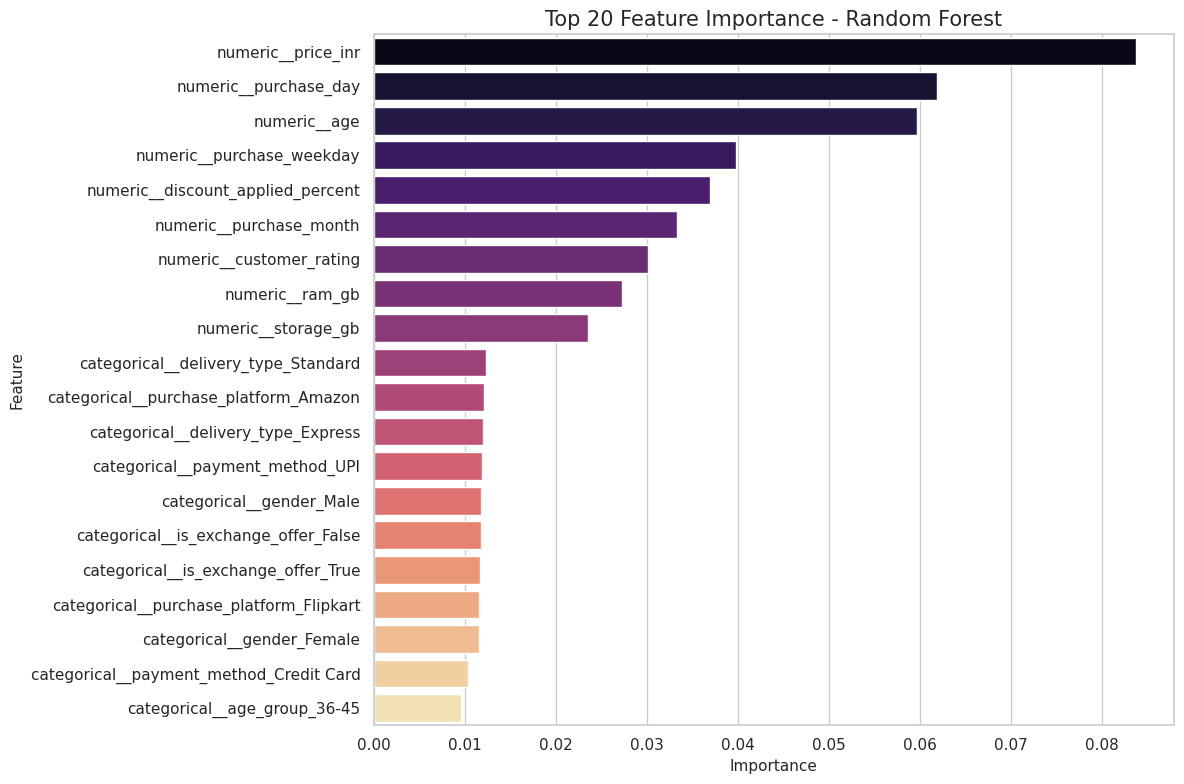


========== FINAL ML SUMMARY ==========
Total Records: 1000000
Training Records: 800000
Testing Records: 200000
Target Variable: feedback_sentiment
Target Classes: ['Negative', 'Neutral', 'Positive']
Algorithms Evaluated: 6
Best Model: Random Forest

Machine Learning Pipeline Completed Successfully!


In [13]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler, label_binarize
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report,
    roc_curve, auc, roc_auc_score
)

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier
)
from sklearn.neighbors import KNeighborsClassifier


# ============================================================
# 2. DATA CLEANING
# ============================================================

df = df.drop_duplicates().copy()

df.columns = df.columns.str.strip()

df['purchase_date'] = pd.to_datetime(
    df['purchase_date'], errors='coerce'
)

# Extract date features
df['purchase_year'] = df['purchase_date'].dt.year
df['purchase_month'] = df['purchase_date'].dt.month
df['purchase_day'] = df['purchase_date'].dt.day
df['purchase_weekday'] = df['purchase_date'].dt.dayofweek

# Remove original date
df.drop(columns=['purchase_date'], inplace=True)

# ============================================================
# 3. SELECT TARGET VARIABLE
# ============================================================

TARGET = 'feedback_sentiment'

df = df.dropna(subset=[TARGET]).copy()

print("\nTarget Distribution:")
print(df[TARGET].value_counts())

# Remove identifier and target leakage/unhelpful columns
drop_columns = [
    'customer_id',
    'first_name',
    'last_name',
    'pincode'
]

df.drop(
    columns=[c for c in drop_columns if c in df.columns],
    inplace=True
)

# ============================================================
# 4. PREPARE FEATURES AND TARGET
# ============================================================

X = df.drop(columns=[TARGET])
y = df[TARGET].astype(str)

# Encode target labels
target_encoder = LabelEncoder()
y_encoded = target_encoder.fit_transform(y)

class_names = target_encoder.classes_

print("\nTarget Classes:", class_names)
print("Number of Classes:", len(class_names))

# Identify numeric and categorical columns
numeric_features = X.select_dtypes(
    include=['int64', 'float64', 'int32', 'float32']
).columns.tolist()

categorical_features = X.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

print("\nNumeric Features:", numeric_features)
print("\nCategorical Features:", categorical_features)

# ============================================================
# 5. TRAIN TEST SPLITTING
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("\nTraining Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

# ============================================================
# 6. DATA PREPROCESSING
# ============================================================

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=True
    ))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('numeric', numeric_transformer, numeric_features),
        ('categorical', categorical_transformer, categorical_features)
    ],
    remainder='drop'
)

# Fit only on training data
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("\nProcessed Training Shape:", X_train_processed.shape)
print("Processed Testing Shape:", X_test_processed.shape)

# ============================================================
# 7. DEFINE MACHINE LEARNING ALGORITHMS
# ============================================================

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=500,
        class_weight='balanced',
        n_jobs=-1
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=15,
        min_samples_split=10,
        class_weight='balanced',
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=15,
        min_samples_split=10,
        class_weight='balanced',
        n_jobs=-1,
        random_state=42
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=100,
        max_depth=15,
        class_weight='balanced',
        n_jobs=-1,
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=80,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5,
        n_jobs=-1
    ),

    "Hist Gradient Boosting": HistGradientBoostingClassifier(
        max_iter=100,
        learning_rate=0.1,
        max_leaf_nodes=20,
        random_state=42
    )
}

# ============================================================
# 8. TRAIN MODELS AND EVALUATE
# ============================================================

results = []
trained_models = {}
roc_data = {}

n_classes = len(class_names)

for name, model in models.items():

    print("\n" + "=" * 65)
    print("Training:", name)

    try:
        # Train
        model.fit(X_train_processed, y_train)

        # Predict
        y_pred = model.predict(X_test_processed)

        # Prediction probabilities
        y_prob = model.predict_proba(X_test_processed)

        # Metrics
        accuracy = accuracy_score(y_test, y_pred)

        precision = precision_score(
            y_test, y_pred,
            average='weighted',
            zero_division=0
        )

        recall = recall_score(
            y_test, y_pred,
            average='weighted',
            zero_division=0
        )

        f1 = f1_score(
            y_test, y_pred,
            average='weighted',
            zero_division=0
        )

        # ROC AUC
        if n_classes == 2:
            roc_auc = roc_auc_score(y_test, y_prob[:, 1])
        else:
            roc_auc = roc_auc_score(
                y_test,
                y_prob,
                multi_class='ovr',
                average='weighted'
            )

        print("Accuracy :", round(accuracy * 100, 2), "%")
        print("Precision:", round(precision * 100, 2), "%")
        print("Recall   :", round(recall * 100, 2), "%")
        print("F1 Score :", round(f1 * 100, 2), "%")
        print("ROC AUC  :", round(roc_auc, 4))

        results.append({
            'Model': name,
            'Accuracy': accuracy * 100,
            'Precision': precision * 100,
            'Recall': recall * 100,
            'F1 Score': f1 * 100,
            'ROC AUC': roc_auc
        })

        trained_models[name] = model

        # Confusion matrix
        cm = confusion_matrix(
            y_test,
            y_pred,
            labels=np.arange(n_classes)
        )

        plt.figure(figsize=(8, 6))

        sns.heatmap(
            cm,
            annot=True,
            fmt='d',
            cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names
        )

        plt.title(f'{name} - Confusion Matrix')
        plt.xlabel('Predicted')
        plt.ylabel('Actual')
        plt.tight_layout()
        plt.show()
        plt.close()

        # Store ROC information
        roc_data[name] = y_prob

    except Exception as e:
        print("Model Error:", str(e))

# ============================================================
# 9. MODEL COMPARISON
# ============================================================

results_df = pd.DataFrame(results)

if results_df.empty:
    raise ValueError("All models failed. Check preprocessing and target classes.")

results_df = results_df.sort_values(
    by='ROC AUC',
    ascending=False
).reset_index(drop=True)

print("\n========== MODEL PERFORMANCE COMPARISON ==========")
display(results_df.round(4))

# ============================================================
# 10. ACCURACY COMPARISON
# ============================================================

plt.figure(figsize=(13, 6))

sns.barplot(
    data=results_df,
    x='Model',
    y='Accuracy',
    hue='Model',
    palette='viridis',
    legend=False
)

plt.title("Machine Learning Model Accuracy Comparison")
plt.ylabel("Accuracy (%)")
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 11. PRECISION, RECALL AND F1 COMPARISON
# ============================================================

comparison = results_df.melt(
    id_vars='Model',
    value_vars=['Precision', 'Recall', 'F1 Score'],
    var_name='Metric',
    value_name='Score'
)

plt.figure(figsize=(14, 7))

sns.barplot(
    data=comparison,
    x='Model',
    y='Score',
    hue='Metric',
    palette='Set2'
)

plt.title("Precision, Recall and F1 Score Comparison")
plt.ylabel("Score (%)")
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 12. ROC CURVE - BINARY OR MULTICLASS
# ============================================================

plt.figure(figsize=(11, 8))

for name, y_prob in roc_data.items():

    if n_classes == 2:

        fpr, tpr, _ = roc_curve(
            y_test,
            y_prob[:, 1]
        )

        roc_auc = auc(fpr, tpr)

        plt.plot(
            fpr,
            tpr,
            linewidth=2,
            label=f'{name} (AUC = {roc_auc:.3f})'
        )

    else:

        y_test_binary = label_binarize(
            y_test,
            classes=np.arange(n_classes)
        )

        fpr, tpr, _ = roc_curve(
            y_test_binary.ravel(),
            y_prob.ravel()
        )

        roc_auc = auc(fpr, tpr)

        plt.plot(
            fpr,
            tpr,
            linewidth=2,
            label=f'{name} (Micro AUC = {roc_auc:.3f})'
        )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    color='black',
    label='Random Classifier'
)

plt.title("ROC Curve - Machine Learning Models")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc='lower right', fontsize=8)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
plt.close()

# ============================================================
# 13. BEST MODEL
# ============================================================

best_model_name = results_df.iloc[0]['Model']
best_model = trained_models[best_model_name]

print("\n========== BEST MODEL ==========")
print("Best Model:", best_model_name)

best_predictions = best_model.predict(X_test_processed)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        best_predictions,
        labels=np.arange(n_classes),
        target_names=class_names,
        zero_division=0
    )
)

# ============================================================
# 14. FEATURE IMPORTANCE
# ============================================================

if hasattr(best_model, 'feature_importances_'):

    feature_names = preprocessor.get_feature_names_out()

    importance = pd.DataFrame({
        'Feature': feature_names,
        'Importance': best_model.feature_importances_
    })

    importance = importance.sort_values(
        by='Importance',
        ascending=False
    ).head(20)

    plt.figure(figsize=(12, 8))

    sns.barplot(
        data=importance,
        x='Importance',
        y='Feature',
        hue='Feature',
        palette='magma',
        legend=False
    )

    plt.title(f"Top 20 Feature Importance - {best_model_name}")
    plt.tight_layout()
    plt.show()
    plt.close()

# ============================================================
# 15. FINAL SUMMARY
# ============================================================

print("\n========== FINAL ML SUMMARY ==========")

print("Total Records:", len(df))
print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))
print("Target Variable:", TARGET)
print("Target Classes:", list(class_names))
print("Algorithms Evaluated:", len(trained_models))
print("Best Model:", best_model_name)

print("\nMachine Learning Pipeline Completed Successfully!")


## Thank you..pls upvote!!!!!!!!!!